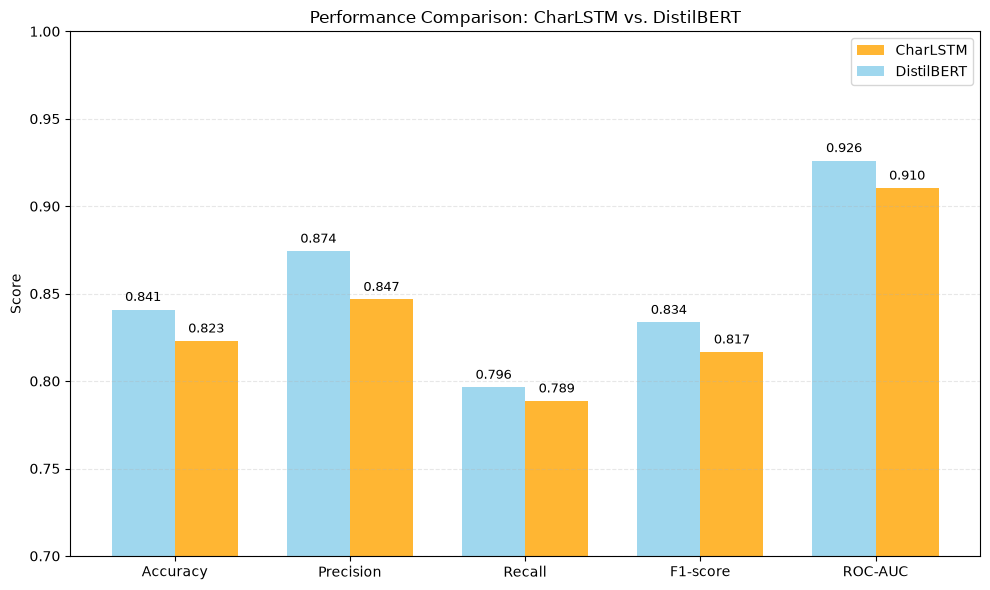

In [2]:
import numpy as np
import matplotlib.pyplot as plt

charlstm_results = {
    "accuracy": 0.8228759117036178,
    "precision": 0.8466524918321838,
    "recall": 0.7885813650195623,
    "f1": 0.8165858050317611,
    "roc_auc": 0.9102918076873906,
}
distilbert_results = {
    "accuracy": 0.8409248257096396,
    "precision": 0.8742466286077873,
    "recall": 0.7964063179249384,
    "f1": 0.8335130763008898,
    "roc_auc": 0.9260381742397056,
}


# Metrics to display
metrics = [
    ("accuracy", "Accuracy"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1-score"),
    ("roc_auc", "ROC-AUC"),
]

char_values = [charlstm_results[key] for key, _ in metrics]
distilbert_values = [distilbert_results[key] for key, _ in metrics]
labels = [label for _, label in metrics]

# Bar positions
x = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

bars_char = ax.bar(
    x + width / 2,
    char_values,
    width,
    label="CharLSTM",
    color="#ffb633",
)

bars_distilbert = ax.bar(
    x - width / 2,
    distilbert_values,
    width,
    label="DistilBERT",
    color="#9fd7ee",
)

# Add values above bars
for bars in [bars_distilbert,bars_char]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

# Formatting
ax.set_ylabel("Score")
ax.set_title("Performance Comparison: CharLSTM vs. DistilBERT")
ax.set_xticks(x)
ax.set_xticklabels(labels)

# Metrics are all between 0 and 1
ax.set_ylim(0.70, 1.0)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=1200, bbox_inches='tight')
plt.show()